# Laboratorio: Implementar un perceptron con un dataset real

Aplicamos un perceptrón simple al conjunto de datos real *Adult / Census Income* (UCI). Este dataset contiene información demográfica de 45,222 personas con el objetivo de predecir si los ingresos anuales de un individuo superan los 50,000 USD.

## Funcionamiento de la red neuronal

La función de optimización `entrena()` es abstracta e independiente del significado de los datos. Para asegurar su correcta ejecución matemática, el conjunto de datos debe cumplir con las siguientes condiciones estructurales:

*   **Entradas numéricas ($X$):** Los datos deben estructurarse en una matriz numérica de tipo flotante de dimensiones $(n, m)$, dado que el modelo opera mediante multiplicaciones de matrices.
*   **Salida binaria ($y$):** La variable objetivo debe estar codificada estrictamente como un vector binario con valores en el conjunto $\{0, 1\}$, asegurando la compatibilidad con el rango analítico de la función sigmoide.
*   **Homogeneidad de escalas:** Las variables continuas deben presentar rangos de magnitud comparables para evitar que los gradientes de las variables de mayor escala monopolicen la actualización de los pesos.
*   **Término de sesgo (bias):** Se requiere añadir una columna de valores constantes unitarios a la matriz de diseño. Esto permite desplazar la frontera de decisión lineal fuera del origen del espacio coordenado.

## 0. Configuración del entorno de desarrollo

Para esta extensión del experimento, incorporamos la biblioteca `pandas` para la manipulación estructurada de datos y la codificación de variables cualitativas. Asimismo, empleamos `sklearn` de manera auxiliar para realizar la partición de muestras, la estandarización de las características y el cálculo de métricas de rendimiento. La estructura interna, los pesos y el algoritmo de optimización del perceptrón se codifican directamente sin recurrir a librerías externas.

In [ ]:
import io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

# Estilo de las figuras de matplotlib
SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
SERIE = ["#2a78d6", "#eb6834", "#1baf7a"]   # azul, naranja, aqua
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK_2,
    "text.color": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "font.size": 10, "figure.dpi": 110,
})
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


## 1. Descarga y limpieza de datos

Consolidamos las particiones originales de entrenamiento (`adult.data`) y prueba (`adult.test`) en un único conjunto de datos para aplicar una estrategia de validación personalizada. Durante este proceso, se resuelven problemas de calidad de datos mediante la exclusión de registros nulos codificados como `?`, la eliminación de espacios en blanco en cadenas de texto y la homologación de la etiqueta de clase objetivo (`>50K` frente a `>50K.` con punto final).

In [ ]:
COLS = ["age","workclass","fnlwgt","education","education_num","marital_status",
        "occupation","relationship","race","sex","capital_gain","capital_loss",
        "hours_per_week","native_country","income"]

URL = "https://archive.ics.uci.edu/static/public/2/adult.zip"
z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(URL).read()))
print("archivos en el zip:", z.namelist())

def leer(nombre, saltar):
    return pd.read_csv(z.open(nombre), names=COLS, skiprows=saltar,
                       skipinitialspace=True, na_values="?")

df = pd.concat([leer("adult.data", 0), leer("adult.test", 1)], ignore_index=True)
print("filas crudas          :", len(df))

df = df.dropna()                      # descarta filas con "?" en alguna columna
print("filas tras dropna     :", len(df))

df["income"] = df["income"].str.rstrip(".").map({"<=50K": 0, ">50K": 1})
print("nulos en el target    :", int(df["income"].isna().sum()), "(debe ser 0)")
print("proporción de >50K    :", round(df["income"].mean(), 4))
df.head()

archivos en el zip: ['Index', 'adult.data', 'adult.names', 'adult.test', 'old.adult.names']
filas crudas          : 48842
filas tras dropna     : 45222
nulos en el target    : 0 (debe ser 0)
proporción de >50K    : 0.2478


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0


## 2. Análisis e inspección de variables

El análisis descriptivo inicial revela asimetrías severas en las escalas de las variables continuas. Por ejemplo, el peso demográfico ponderado (`fnlwgt`) alcanza valores en el orden de millones, mientras que los años de educación (`education_num`) están acotados a un máximo de 16. Esta disparidad de escalas exige la aplicación de un protocolo de estandarización para asegurar que todas las características tengan la misma influencia en el cálculo del descenso de gradiente.

In [ ]:
y_serie = df["income"]
feats = df.drop(columns="income")

num = feats.select_dtypes(include="number").columns.tolist()
cat = feats.select_dtypes(exclude="number").columns.tolist()

print(f"NUMÉRICAS ({len(num)}): {num}\n")
print(f"CATEGÓRICAS ({len(cat)}):")
total_dummies = 0
for c in cat:
    k = feats[c].nunique()
    total_dummies += k - 1
    print(f"  {c:18s} {k:3d} categorías -> {k-1:3d} dummies")

print(f"\n  {total_dummies} dummies + {len(num)} numéricas = {total_dummies + len(num)} variables")
print("\nRangos crudos de las numéricas:")
feats[num].describe().loc[["min", "max", "mean", "std"]].T.round(1)

NUMÉRICAS (6): ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

CATEGÓRICAS (8):
  workclass            7 categorías ->   6 dummies
  education           16 categorías ->  15 dummies
  marital_status       7 categorías ->   6 dummies
  occupation          14 categorías ->  13 dummies
  relationship         6 categorías ->   5 dummies
  race                 5 categorías ->   4 dummies
  sex                  2 categorías ->   1 dummies
  native_country      41 categorías ->  40 dummies

  90 dummies + 6 numéricas = 96 variables

Rangos crudos de las numéricas:


,min,max,mean,std
age,17.0,90.0,38.5,13.2
fnlwgt,13492.0,1490400.0,189734.7,105639.2
education_num,1.0,16.0,10.1,2.6
capital_gain,0.0,99999.0,1101.4,7506.4
capital_loss,0.0,4356.0,88.6,405.0
hours_per_week,1.0,99.0,40.9,12.0


## 3. Codificación de variables categóricas (One-Hot Encoding)

Transformamos las variables de texto en columnas numéricas binarias (0 o 1) utilizando la función `pd.get_dummies`. Para evitar problemas de multicolinealidad, se aplica el parámetro `drop_first=True`, eliminando la primera categoría de cada variable. Esto previene la redundancia algebraica conocida como la **trampa de la variable dummy**, la cual distorsiona la estimación única de los parámetros y afecta la interpretabilidad del modelo.

In [ ]:
y = y_serie.to_numpy().astype(int)
X = pd.get_dummies(feats, drop_first=True).to_numpy(dtype=float)

print("X:", X.shape, "  dtype:", X.dtype)
print("y:", y.shape, "  valores:", np.unique(y), "  positivos:", round(y.mean(), 4))

nombres = pd.get_dummies(feats, drop_first=True).columns.tolist()
print("\nprimeras 8 variables :", nombres[:8])
print("últimas 3 variables  :", nombres[-3:])

X: (45222, 96)   dtype: float64
y: (45222,)   valores: [0 1]   positivos: 0.2478

primeras 8 variables : ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'workclass_Local-gov', 'workclass_Private']
últimas 3 variables  : ['native_country_United-States', 'native_country_Vietnam', 'native_country_Yugoslavia']


## 4. Partición y protocolo de escalado

Para garantizar la validez del experimento, implementamos dos controles metodológicos:

*   **Estratificación de la muestra (`stratify=y`):** Asegura que la baja proporción de la clase positiva (24.8% de observaciones con ingresos superiores a 50K) se preserve de manera idéntica tanto en el conjunto de entrenamiento como en el de validación.
*   **Prevención de fuga de información (*Data Leakage*):** Los parámetros de la estandarización (media y desviación estándar) se calculan únicamente a partir del conjunto de entrenamiento y se aplican posteriormente para transformar ambos conjuntos de datos.

In [ ]:
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print(f"entrenamiento: {Xtr.shape[0]:>6,} filas  ({ytr.mean():.1%} positivos)")
print(f"prueba       : {Xte.shape[0]:>6,} filas  ({yte.mean():.1%} positivos)")

sc = StandardScaler().fit(Xtr)     # aprende media y desviación SOLO del train
Xtr = sc.transform(Xtr)
Xte = sc.transform(Xte)

print("\ntras escalar (train): media ~", round(Xtr.mean(), 6),
      " desviación ~", round(Xtr.std(), 4))

entrenamiento: 31,655 filas  (24.8% positivos)
prueba       : 13,567 filas  (24.8% positivos)

tras escalar (train): media ~ -0.0  desviación ~ 1.0


## 5. Arquitectura del modelo y algoritmo de aprendizaje

Adaptamos la estructura original del perceptrón para asegurar su estabilidad en un escenario de alta dimensionalidad mediante tres ajustes:

1.  **Inclusión del sesgo:** Añadimos un vector de unos a la matriz de diseño, expandiendo la frontera de decisión lineal.
2.  **Inicialización acotada:** Los pesos se inicializan con valores pequeños en el intervalo $[-1, 1)$ para evitar la saturación prematura de la función sigmoide.
3.  **Gradiente promediado:** Dividimos la actualización de los pesos por el tamaño de la muestra ($n$) e incorporamos una tasa de aprendizaje (`lr`) para estabilizar los ajustes matemáticos.

La regla de actualización responde a la siguiente ecuación analítica:

```python
w += lr * (X.T @ ((y - out) * out * (1 - out))) / n
```

Donde se multiplica el error residual (`y - out`) por la derivada de la función sigmoide (`out * (1 - out)`), proyectando este ajuste sobre los valores de entrada de cada característica (`X.T`).

In [ ]:
def entrena(X, y, iteraciones=3000, lr=0.5, seed=1, cada=50):
    '''Entrena una neurona sigmoide. Devuelve (pesos, historial_ecm).'''
    rng = np.random.RandomState(seed)
    X = np.hstack([X, np.ones((len(X), 1))])        # columna de sesgo
    w = 2 * rng.random((X.shape[1], 1)) - 1         # pesos iniciales en [-1, 1)
    y = y.reshape(-1, 1)
    n = len(X)
    historial = []

    for i in range(iteraciones):
        out = 1 / (1 + np.exp(-(X @ w)))            # suma ponderada -> sigmoide
        error = y - out
        w += lr * (X.T @ (error * out * (1 - out))) / n
        if i % cada == 0:
            historial.append((i, float(np.mean(error ** 2))))

    return w, np.array(historial)


def prob(X, w):
    '''Probabilidad predicha para cada fila (añade el sesgo por su cuenta).'''
    X = np.hstack([X, np.ones((len(X), 1))])
    return (1 / (1 + np.exp(-(X @ w)))).ravel()


w, hist = entrena(Xtr, ytr)
print("forma de w:", w.shape, " (96 variables + 1 sesgo)")
print("sesgo aprendido:", round(float(w[-1, 0]), 4))
print("ECM inicial:", round(hist[0, 1], 4), "-> final:", round(hist[-1, 1], 4))

forma de w: (97, 1)  (96 variables + 1 sesgo)
sesgo aprendido: -1.7675
ECM inicial: 0.4812 -> final: 0.1196


### Evaluación de la convergencia del modelo

El seguimiento del error cuadrático medio (ECM) a lo largo de las iteraciones permite verificar el comportamiento del entrenamiento. Una curva asintótica y descendente valida la convergencia del algoritmo hacia un mínimo estable.

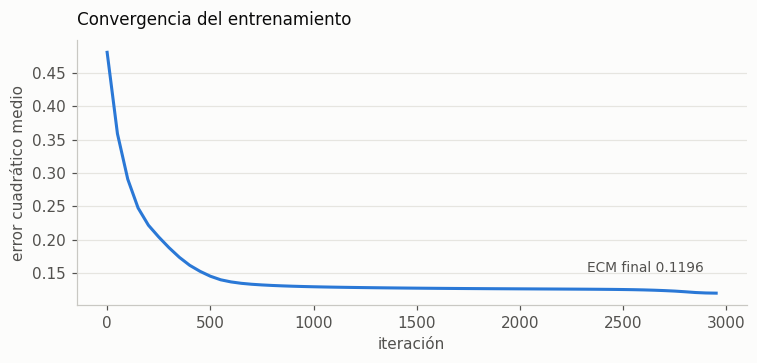

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(hist[:, 0], hist[:, 1], color=SERIE[0], linewidth=2)
ax.set_xlabel("iteración")
ax.set_ylabel("error cuadrático medio")
ax.set_title("Convergencia del entrenamiento", color=INK, fontsize=11, loc="left", pad=10)
ax.grid(True, axis="y")
ax.set_axisbelow(True)

# etiqueta directa del valor final
ax.annotate(f"ECM final {hist[-1, 1]:.4f}",
            xy=(hist[-1, 0], hist[-1, 1]), xytext=(-8, 14),
            textcoords="offset points", ha="right", color=INK_2, fontsize=9)
plt.tight_layout()
plt.show()

## 6. Evaluación de Rendimiento y Análisis de Métricas

Evaluamos el rendimiento del perceptrón mediante dos enfoques complementarios. Por un lado, utilizamos métricas sujetas al umbral de clasificación estándar de 0.5 (exactitud, precisión, exhaustividad y puntuación F1). Por otro lado, calculamos el área bajo la curva ROC (AUC), que evalúa de forma global la calidad de la ordenación probabilística del modelo de manera independiente del umbral.

Establecemos como **baseline** una exactitud de 0.752, correspondiente a un clasificador ingenuo que asigne siempre la clase mayoritaria (`<=50K`). Toda evaluación del modelo debe interpretarse como una mejora marginal sobre este valor de referencia.

In [ ]:
p = prob(Xte, w)                      # probabilidades continuas en (0,1)
pred = (p > 0.5).astype(int)          # decisión binaria con umbral 0.5

baseline = 1 - yte.mean()             # acertar siempre "<=50K"

print(f"baseline (predecir siempre 0) : {baseline:.4f}")
print(f"accuracy                      : {accuracy_score(yte, pred):.4f}")
print(f"  -> mejora sobre el baseline : {accuracy_score(yte, pred) - baseline:+.4f}")
print()
print(f"precision : {precision_score(yte, pred):.4f}   (de los que predije >50K, ¿cuántos lo eran?)")
print(f"recall    : {recall_score(yte, pred):.4f}   (de los que ganaban >50K, ¿cuántos detecté?)")
print(f"f1        : {f1_score(yte, pred):.4f}   (media armónica de las dos)")
print(f"roc_auc   : {roc_auc_score(yte, p):.4f}   (calidad del ordenamiento, independiente del umbral)")

baseline (predecir siempre 0) : 0.7522
accuracy                      : 0.8293
  -> mejora sobre el baseline : +0.0771

precision : 0.6784   (de los que predije >50K, ¿cuántos lo eran?)
recall    : 0.5916   (de los que ganaban >50K, ¿cuántos detecté?)
f1        : 0.6320   (media armónica de las dos)
roc_auc   : 0.8701   (calidad del ordenamiento, independiente del umbral)


### Análisis de la Matriz de Confusión

La matriz de confusión detalla el balance de aciertos y errores en sus cuatro categorías:

```
                 predicho <=50K   predicho >50K
real <=50K            VN               FP        <- falsos positivos
real  >50K            FN               VP        <- falsos negativos
```

Los resultados muestran un nivel de exhaustividad (*recall*) limitado. El modelo presenta dificultades para detectar de manera oportuna a los individuos de ingresos altos, clasificando erróneamente a una fracción significativa de ellos en la categoría opuesta (falsos negativos).

In [ ]:
cm = confusion_matrix(yte, pred)
vn, fp, fn, vp = cm.ravel()

print(pd.DataFrame(cm,
                   index=["real <=50K", "real  >50K"],
                   columns=["pred <=50K", "pred >50K"]))
print()
print(f"verdaderos negativos (VN): {vn:>5,}   correctos <=50K")
print(f"falsos positivos     (FP): {fp:>5,}   dije >50K y no lo era")
print(f"falsos negativos     (FN): {fn:>5,}   gana >50K y no lo detecté  <-- el problema")
print(f"verdaderos positivos (VP): {vp:>5,}   correctos >50K")
print()
print(f"recall = VP / (FN + VP) = {vp} / ({fn} + {vp}) = {vp / (fn + vp):.4f}")

            pred <=50K  pred >50K
real <=50K        9262        943
real  >50K        1373       1989

verdaderos negativos (VN): 9,262   correctos <=50K
falsos positivos     (FP):   943   dije >50K y no lo era
falsos negativos     (FN): 1,373   gana >50K y no lo detecté  <-- el problema
verdaderos positivos (VP): 1,989   correctos >50K

recall = VP / (FN + VP) = 1989 / (1373 + 1989) = 0.5916


## 7. Experimento: Optimización del Umbral de Decisión

El umbral de clasificación de 0.50 puede modificarse para balancear el comportamiento del modelo. Al disminuir este valor, se facilita la clasificación en la clase positiva, aumentando la exhaustividad (*recall*) a costa de reducir la precisión. Evaluamos un barrido de umbrales utilizando la métrica *F1-score* (media armónica entre precisión y exhaustividad) como criterio de optimización para encontrar el punto de equilibrio óptimo.

In [ ]:
umbrales = np.linspace(0.05, 0.95, 91)
filas = []
for u in umbrales:
    d = (p > u).astype(int)
    filas.append((u,
                  precision_score(yte, d, zero_division=0),
                  recall_score(yte, d, zero_division=0),
                  f1_score(yte, d, zero_division=0)))
barrido = pd.DataFrame(filas, columns=["umbral", "precision", "recall", "f1"])

mejor = barrido.loc[barrido.f1.idxmax()]
print(f"mejor F1 = {mejor.f1:.4f} con umbral = {mejor.umbral:.2f}")
print(f"  precision {mejor.precision:.4f} | recall {mejor.recall:.4f}")
print(f"\ncontra el umbral 0.5: F1 {f1_score(yte, pred):.4f} "
      f"| precision {precision_score(yte, pred):.4f} | recall {recall_score(yte, pred):.4f}")

# tabla de apoyo (los valores exactos, no solo la figura)
print("\n" + "-" * 46)
print(barrido[barrido.umbral.round(2).isin([0.10, 0.20, 0.30, 0.40, 0.50, 0.70, 0.90])]
      .round(4).to_string(index=False))

mejor F1 = 0.6694 con umbral = 0.27
  precision 0.5648 | recall 0.8215

contra el umbral 0.5: F1 0.6320 | precision 0.6784 | recall 0.5916

----------------------------------------------
 umbral  precision  recall     f1
    0.1     0.4476  0.9358 0.6056
    0.2     0.5195  0.8819 0.6539
    0.3     0.5818  0.7835 0.6678
    0.4     0.6352  0.6874 0.6603
    0.5     0.6784  0.5916 0.6320
    0.7     0.7378  0.3908 0.5110
    0.9     0.6857  0.1889 0.2962


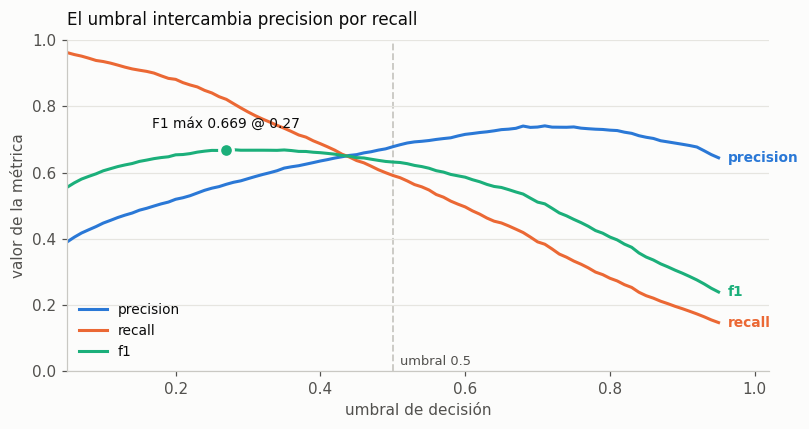

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for col, color in zip(["precision", "recall", "f1"], SERIE):
    ax.plot(barrido.umbral, barrido[col], color=color, linewidth=2, label=col)
    # etiqueta directa al final de cada curva (la identidad no depende solo del color)
    ax.annotate(col, xy=(barrido.umbral.iloc[-1], barrido[col].iloc[-1]),
                xytext=(6, 0), textcoords="offset points",
                color=color, fontsize=9, va="center", fontweight="bold")

ax.axvline(0.5, color="#c9c8c3", linewidth=1.2, linestyle="--", zorder=0)
ax.annotate("umbral 0.5", xy=(0.5, 0.02), xytext=(5, 0), textcoords="offset points",
            color=INK_2, fontsize=8.5)
ax.plot(mejor.umbral, mejor.f1, "o", color=SERIE[2], markersize=9,
        markeredgecolor=SURFACE, markeredgewidth=2, zorder=5)
ax.annotate(f"F1 máx {mejor.f1:.3f} @ {mejor.umbral:.2f}",
            xy=(mejor.umbral, mejor.f1), xytext=(0, 14),
            textcoords="offset points", ha="center", color=INK, fontsize=9)

ax.set_xlabel("umbral de decisión")
ax.set_ylabel("valor de la métrica")
ax.set_title("El umbral intercambia precision por recall", color=INK,
             fontsize=11, loc="left", pad=10)
ax.set_xlim(0.05, 1.02); ax.set_ylim(0, 1)
ax.grid(True, axis="y"); ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

## 8. Coeficientes e Interferencia del Escalado

La estandarización permite comparar los pesos para interpretar la relevancia de cada variable. Sin embargo, este proceso introduce un sesgo metodológico: las variables raras de baja frecuencia presentan desviaciones estándar muy pequeñas y reciben, por consecuencia, valores artificialmente altos tras el escalado. Esto infla sus pesos asociados sin que representen una verdadera importancia predictiva.

Para corregir esta distorsión, filtramos el análisis conservando exclusivamente las características con una prevalencia muestral igual o superior al 1%, aislando así el ruido demográfico del análisis explicativo.

In [ ]:
prevalencia = (X != 0).mean(axis=0)          # X sin escalar: fracción de filas no-cero
tabla = pd.DataFrame({"peso": w[:-1].ravel(), "prevalencia": prevalencia}, index=nombres)

print("SIN FILTRAR — los pesos más grandes son casi todos categorías rarísimas:")
print(tabla.reindex(tabla.peso.abs().sort_values(ascending=False).index)
           .head(8).round(4).to_string())

print("\n" + "=" * 60)
frecuentes = tabla[tabla.prevalencia >= 0.01]
print(f"\nSOLO variables presentes en >=1% de las filas ({len(frecuentes)} de {len(tabla)}):\n")
orden = frecuentes.reindex(frecuentes.peso.sort_values(ascending=False).index)
print("Empujan hacia >50K:")
print(orden.head(10).round(4).to_string())
print("\nEmpujan hacia <=50K:")
print(orden.tail(10)[::-1].round(4).to_string())

SIN FILTRAR — los pesos más grandes son casi todos categorías rarísimas:
                              peso  prevalencia
capital_gain                2.0964       0.0838
education_Doctorate         1.2563       0.0120
education_1st-4th          -1.0589       0.0049
native_country_Haiti        0.9916       0.0015
native_country_Thailand     0.9621       0.0006
native_country_Italy        0.9434       0.0022
native_country_Puerto-Rico  0.9431       0.0039
native_country_Poland       0.8964       0.0018


SOLO variables presentes en >=1% de las filas (50 de 96):

Empujan hacia >50K:
                                     peso  prevalencia
capital_gain                       2.0964       0.0838
education_Doctorate                1.2563       0.0120
education_Bachelors                0.3607       0.1674
marital_status_Married-civ-spouse  0.3605       0.4656
sex_Male                           0.3135       0.6750
hours_per_week                     0.3078       1.0000
native_country_United-States 

El análisis de los coeficientes filtrados ofrece una interpretación sólida y alineada con los estudios económicos. Las variables que más favorecen la predicción de ingresos altos son el nivel educativo superior (`Doctorate`, `Bachelors`), el estado civil de matrimonio y las ganancias de capital. En sentido opuesto, las situaciones de soltería, los cargos no profesionales y las familias con hijos dependientes operan como fuertes indicadores de ingresos inferiores a los 50,000 USD.